# Step 1: Prepare the Environment

In [2]:

!pip install ultralytics


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 19.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics] [ultralytics]


In [3]:

import cv2
import ultralytics
from ultralytics import YOLO, solutions

print("OpenCV version:", cv2.__version__)
print("Ultralytics version:", ultralytics.__version__)

print("VisionEye solution available:", hasattr(solutions, "VisionEye"))


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
OpenCV version: 4.14.0
Ultralytics version: 8.4.220
VisionEye solution available: True


## What is VisionEye?

VisionEye is an Ultralytics solution that visualizes the relationship between a fixed observation point and detected objects by drawing lines from the observation point to each object.

## Why is VisionEye useful?

Helps visualize object positions from a specific viewpoint.

Useful in visual monitoring and surveillance systems.

Provides a clearer understanding of spatial relationships between objects.

## Difference Between VisionEye and Normal Object Detection

Normal object detection identifies objects and draws bounding boxes around them, while VisionEye adds visual mapping lines connecting a selected observation point to detected objects.

# Step 2: Load a Video File

Video loaded successfully!
Width: 1080
Height: 1920
FPS: 60.0
Total Frames: 958


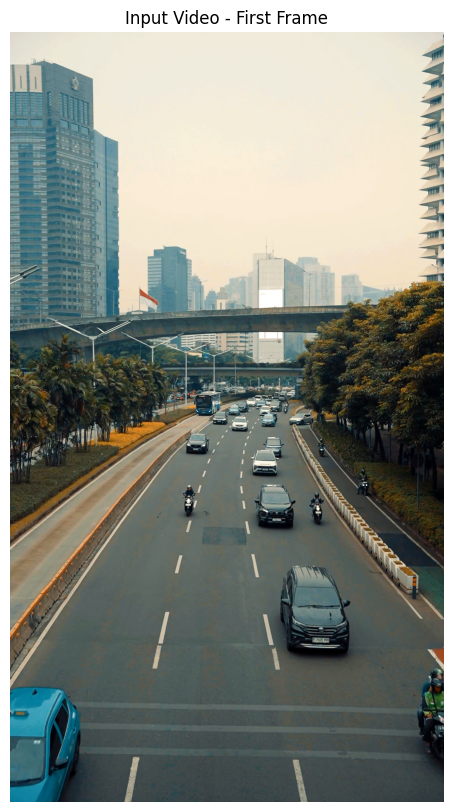

In [4]:

import os
import cv2
import matplotlib.pyplot as plt

# Input video path
video_path = "/kaggle/input/datasets/youssefyasser74/traffic-video-compressed/Traffic Compressed.mp4"

# Open video
cap = cv2.VideoCapture(video_path)

# Check if video opened successfully
if not cap.isOpened():
    print("Error: Could not open video")
else:
    # Extract video properties
    frame_width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    frame_height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps = cap.get(cv2.CAP_PROP_FPS)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    print("Video loaded successfully!")
    print("Width:", frame_width)
    print("Height:", frame_height)
    print("FPS:", fps)
    print("Total Frames:", total_frames)

    # Read first frame
    ret, frame = cap.read()

    if ret:
        frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

        plt.figure(figsize=(8, 10))
        plt.imshow(frame_rgb)
        plt.title("Input Video - First Frame")
        plt.axis("off")
        plt.show()


## Why Video Quality Matters

Video quality affects object detection accuracy. Low resolution, poor lighting, motion blur, and unclear objects may reduce detection performance.

## Why Frame Size and FPS Are Required

Frame Width and Height determine the video resolution and are required when creating the output video.

FPS represents the number of frames displayed per second and helps maintain the original video playback speed.

## Why Some Videos May Not Produce Good Detections

Some videos may contain small, blurry, partially hidden, or poorly illuminated objects, making them difficult for YOLO to detect accurately.

# Step 3: Initialize VisionEye

In [5]:

# Initialize VisionEye
visioneye = solutions.VisionEye(
    model="yolo11n.pt",
    classes=[0, 2, 3, 5, 9],
    vision_point=(540, 1800),
    show=False,
    verbose=False
)

print("VisionEye initialized successfully!")
print("Model: YOLO11n")
print("Selected classes:", [0, 2, 3, 5, 9])
print("Vision point:", (540, 1800))


Ultralytics Solutions: ✅ {'source': None, 'model': 'yolo11n.pt', 'classes': [0, 2, 3, 5, 9], 'show_conf': True, 'show_labels': True, 'show_boxes': True, 'region': None, 'colormap': 21, 'show_in': True, 'show_out': True, 'up_angle': 145.0, 'down_angle': 90.0, 'kpts': [6, 8, 10], 'analytics_type': 'line', 'figsize': (12.8, 7.2), 'blur_ratio': 0.5, 'vision_point': (540, 1800), 'crop_dir': 'cropped-detections', 'json_file': None, 'line_width': 2, 'records': 5, 'fps': 30.0, 'max_hist': 5, 'meter_per_pixel': 0.05, 'max_speed': 120, 'show': False, 'iou': None, 'conf': 0.25, 'device': None, 'max_det': 300, 'quantize': None, 'imgsz': 640, 'tracker': 'tracktrack.yaml', 'verbose': False, 'data': 'images', 'recognizer': 'paddleocr'}
WARNING ⚠️ Environment does not support cv2.imshow() or PIL Image.show()

VisionEye initialized successfully!
Model: YOLO11n
Selected classes: [0, 2, 3, 5, 9]
Vision point: (540, 1800)


## Class Filtering:

Class filtering means selecting specific object categories that the model should detect and track.

The selected classes are:

Person (0)

Car (2)

Motorcycle (3)

Bus (5)

Traffic Light (9)

## Why Use Class Filtering?

Focuses on objects relevant to the project.

Reduces unnecessary detections.

Improves visualization clarity.

Can reduce processing workload.

## Vision Point:

The observation point is set to (540, 1800), representing a fixed viewpoint near the bottom center of the video frame.

# Step 4: Process the Video Frame by Frame

In [18]:
import cv2
import os

# Reopen the input video
cap = cv2.VideoCapture(video_path)

# Get video properties
frame_width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
frame_height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = cap.get(cv2.CAP_PROP_FPS)

# Define output video
output_video_path = "/kaggle/working/VisionEye_output3.avi"

# Initialize VideoWriter
fourcc = cv2.VideoWriter_fourcc(*"MJPG")

video_writer = cv2.VideoWriter(
    output_video_path,
    fourcc,
    fps,
    (frame_width, frame_height)
)

# Process all frames
frame_count = 0

if cap.isOpened() and video_writer.isOpened():

    while True:
        success, frame = cap.read()

        if not success:
            break

        # Apply VisionEye mapping
        results = visioneye(frame)

        # Save the processed frame
        video_writer.write(results.plot_im)

        frame_count += 1

else:
    print("Error opening video or output writer!")

# Release resources and finalize output video
cap.release()
video_writer.release()

print("Video processing completed!")
print("Frames processed:", frame_count)
print("Output file size:", os.path.getsize(output_video_path), "bytes")
print("Output saved at:", output_video_path)


Video processing completed!
Frames processed: 958
Output file size: 253628522 bytes
Output saved at: /kaggle/working/VisionEye_output3.avi


## Compress The avi to mp4 to upload on Github

In [19]:

# Compress VisionEye output using H.264

!ffmpeg -y -i /kaggle/working/VisionEye_output3.avi \
-c:v libx264 -preset medium -crf 28 \
-pix_fmt yuv420p -an \
-movflags +faststart \
/kaggle/working/VisionEye_compressed.mp4


ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
  built with gcc 13 (Ubuntu 13.2.0-23ubuntu3)
  configuration: --prefix=/usr --extra-version=3ubuntu5 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --disable-omx --enable-gnutls --enable-libaom --enable-libass --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libglslang --enable-libgme --enable-libgsm --enable-libharfbuzz --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx265 --enable-libxml2 --enable-libxvid --enable-libzimg --ena

In [20]:

import os

compressed_path = "/kaggle/working/VisionEye_compressed.mp4"

size_mb = os.path.getsize(compressed_path) / (1024 * 1024)

print(f"Compressed video size: {size_mb:.2f} MB")


Compressed video size: 4.98 MB
